# 04. Deep Sequence Labeling Architecture: BiLSTM-CRF with Spatial Dropout
## SemEval-2021 Task 5: Toxic Spans Detection

### 1. Architectural Overview: Bidirectional LSTM-CRF
While Linear-Chain CRFs (Notebook 03) rely on hand-crafted surface features, neural **BiLSTM-CRF** architectures (Huang et al., 2015; Lample et al., 2016) learn dense distributed representations alongside global sequence-level tag transitions:

1. **Word + Subword/Character or Fast Contextual Embedding Layer**: Maps discrete token indices $x_t$ into dense vectors $\mathbf{e}_t \in \mathbb{R}^{d_e}$.
2. **Spatial Dropout (`nn.Dropout2d` / 1D Channel Dropout)**: Unlike standard element-wise dropout, **Spatial Dropout** (Tompson et al., 2015) drops entire embedding feature channels across all time steps $t \in [1, T]$ of a sequence. This prevents co-adaptation of embedding dimensions across adjacent tokens.
3. **Stacked Bidirectional LSTM Encoder**:
   $$\overrightarrow{\mathbf{h}}_t = \text{LSTM}_{\text{fwd}}(\mathbf{e}_t, \overrightarrow{\mathbf{h}}_{t-1}), \quad \overleftarrow{\mathbf{h}}_t = \text{LSTM}_{\text{bwd}}(\mathbf{e}_t, \overleftarrow{\mathbf{h}}_{t+1}), \quad \mathbf{h}_t = [\overrightarrow{\mathbf{h}}_t \parallel \overleftarrow{\mathbf{h}}_t]$$
   A linear projection maps $\mathbf{h}_t \in \mathbb{R}^{2 d_h}$ to emission logits $\mathbf{P}_{t} \in \mathbb{R}^{|S|}$.
4. **Linear-Chain CRF Layer (Exact Forward-Backward Loss & Viterbi Decoding)**:
   The score of a tag path $\mathbf{y} = (y_1, \dots, y_T)$ given emission logits $\mathbf{P}$ and learnable transition matrix $\mathbf{A} \in \mathbb{R}^{(|S|+2) \times (|S|+2)}$ is:
   $$s(\mathbf{x}, \mathbf{y}) = \sum_{t=1}^{T} \left( A_{y_{t-1}, y_t} + P_{t, y_t} \right) + A_{y_T, \text{<STOP>}}$$
   During training, we minimize the exact **Negative Log-Likelihood (NLL)** computed via the forward algorithm in log-sum-exp space:
   $$\mathcal{L}_{\text{NLL}}(\mathbf{x}, \mathbf{y}) = \log \sum_{\tilde{\mathbf{y}}} \exp(s(\mathbf{x}, \tilde{\mathbf{y}})) - s(\mathbf{x}, \mathbf{y})$$

In [1]:
import os
import re
import ast
import json
import copy
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing BiLSTM-CRF on device: {DEVICE}")

Executing BiLSTM-CRF on device: cuda


### 2. Loading Data & Creating Train / Validation / Test Splits
We load `tsd_train_bio.csv` and `tsd_test_bio.csv`, and reserve a 10% validation split from the training set to monitor validation **Exact Span Match F1** for **Early Stopping** and learning rate scheduling.

In [2]:
train_df = pd.read_csv("tsd_train_bio.csv")
test_df = pd.read_csv("tsd_test_bio.csv")

X_full_train = [ast.literal_eval(t) for t in train_df["tokens"]]
y_full_train = [ast.literal_eval(b) for b in train_df["bio_tags"]]
X_test = [ast.literal_eval(t) for t in test_df["tokens"]]
y_test = [ast.literal_eval(b) for b in test_df["bio_tags"]]

# 90/10 Train-Validation Split for Early Stopping
num_train = len(X_full_train)
indices = np.random.permutation(num_train)
val_size = int(0.10 * num_train)
val_idx, tr_idx = indices[:val_size], indices[val_size:]

X_train = [X_full_train[i] for i in tr_idx]
y_train = [y_full_train[i] for i in tr_idx]
X_val = [X_full_train[i] for i in val_idx]
y_val = [y_full_train[i] for i in val_idx]

print(f"Train split: {len(X_train):,} | Validation split: {len(X_val):,} | Test split: {len(X_test):,}")

Train split: 7,146 | Validation split: 793 | Test split: 2,000


### 3. Vocabulary Construction, Morphological Features & PyTorch Dataset
In addition to word embeddings, incorporating character/orthographic features (such as capitalization, character suffix, and token toxicity priors from training data) boosts neural sequence labeling on noisy social media text when training from scratch without external gigabyte downloads. We build a vocabulary alongside subword suffix embeddings and pack sequences with dynamic padding masks.

In [3]:
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

TAG2IDX = {"O": 0, "B-TOXIC": 1, "I-TOXIC": 2}
IDX2TAG = {v: k for k, v in TAG2IDX.items()}
START_TAG = 3
STOP_TAG = 4

# Build word and 3-char suffix vocabularies from training split
word_counter = Counter(w.lower() for seq in X_train for w in seq)
suffix_counter = Counter(w.lower()[-3:] for seq in X_train for w in seq)

word2idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for w, c in word_counter.items():
    if c >= 1:
        word2idx[w] = len(word2idx)

suffix2idx = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for s, c in suffix_counter.items():
    if c >= 2:
        suffix2idx[s] = len(suffix2idx)

print(f"Word Vocabulary Size: {len(word2idx):,} | Suffix Vocabulary Size: {len(suffix2idx):,}")

class ToxicSpansDataset(Dataset):
    def __init__(self, X_seqs, y_seqs, word2idx, suffix2idx, max_len=256):
        self.X_seqs = X_seqs
        self.y_seqs = y_seqs
        self.word2idx = word2idx
        self.suffix2idx = suffix2idx
        self.max_len = max_len

    def __len__(self):
        return len(self.X_seqs)

    def __getitem__(self, idx):
        tokens = self.X_seqs[idx][:self.max_len]
        tags = self.y_seqs[idx][:self.max_len]
        if len(tokens) == 0:
            tokens = [UNK_TOKEN]
            tags = ["O"]

        w_ids = [self.word2idx.get(w.lower(), 1) for w in tokens]
        s_ids = [self.suffix2idx.get(w.lower()[-3:], 1) for w in tokens]
        t_ids = [TAG2IDX[t] for t in tags]
        return torch.tensor(w_ids, dtype=torch.long), torch.tensor(s_ids, dtype=torch.long), torch.tensor(t_ids, dtype=torch.long), tokens, tags

def collate_batch(batch):
    w_seqs, s_seqs, t_seqs, raw_tokens, raw_tags = zip(*batch)
    lengths = [len(w) for w in w_seqs]
    max_len = max(lengths)

    padded_w = torch.zeros((len(batch), max_len), dtype=torch.long)
    padded_s = torch.zeros((len(batch), max_len), dtype=torch.long)
    padded_t = torch.zeros((len(batch), max_len), dtype=torch.long)
    mask = torch.zeros((len(batch), max_len), dtype=torch.bool)

    for i, (w, s, t, l) in enumerate(zip(w_seqs, s_seqs, t_seqs, lengths)):
        padded_w[i, :l] = w
        padded_s[i, :l] = s
        padded_t[i, :l] = t
        mask[i, :l] = True

    return padded_w, padded_s, padded_t, mask, raw_tokens, raw_tags

BATCH_SIZE = 64
train_loader = DataLoader(ToxicSpansDataset(X_train, y_train, word2idx, suffix2idx), batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_batch)
val_loader = DataLoader(ToxicSpansDataset(X_val, y_val, word2idx, suffix2idx), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)
test_loader = DataLoader(ToxicSpansDataset(X_test, y_test, word2idx, suffix2idx), batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_batch)

Word Vocabulary Size: 18,221 | Suffix Vocabulary Size: 2,041


### 4. Implementing Spatial Dropout & BiLSTM-CRF Architecture in PyTorch
Below we construct `BiLSTM_CRF`:
- **`SpatialDropout1D`**: Applies `nn.Dropout2d` across the sequence embedding channels `(Batch, Channels, SeqLen)` so entire embedding dimensions are dropped coherently across the sequence.
- **Structural BIO Constraints in the CRF Layer**: We initialize the CRF transition matrix with strong negative penalties ($-10000.0$) for impossible transitions:
  - Transitioning into `<START>` or out of `<STOP>`
  - `<START> -> I-TOXIC` (cannot begin a sequence with `I-TOXIC`)
  - `O -> I-TOXIC` (cannot enter `I-TOXIC` without a preceding `B-TOXIC` or `I-TOXIC`)
- **Vectorized Batched Forward Algorithm & Viterbi Decoder**: Enables fast training on either CPU or GPU.

In [4]:
class SpatialDropout1D(nn.Module):
    """
    Spatial Dropout drops entire feature channels across all timesteps of a sequence.
    Input shape: (batch_size, seq_len, embedding_dim)
    """
    def __init__(self, p: float = 0.3):
        super().__init__()
        self.dropout2d = nn.Dropout2d(p=p)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Permute to (batch_size, embedding_dim, seq_len, 1) for Dropout2d
        x = x.permute(0, 2, 1).unsqueeze(-1)
        x = self.dropout2d(x)
        return x.squeeze(-1).permute(0, 2, 1)


class BiLSTM_CRF(nn.Module):
    def __init__(self, vocab_size: int, suffix_size: int, num_tags: int = 3,
                 word_emb_dim: int = 128, suffix_emb_dim: int = 32,
                 hidden_dim: int = 128, spatial_dropout: float = 0.3):
        super().__init__()
        self.num_tags = num_tags
        self.start_tag = num_tags
        self.stop_tag = num_tags + 1
        self.total_states = num_tags + 2

        self.word_emb = nn.Embedding(vocab_size, word_emb_dim, padding_idx=0)
        self.suffix_emb = nn.Embedding(suffix_size, suffix_emb_dim, padding_idx=0)
        self.spatial_drop = SpatialDropout1D(p=spatial_dropout)

        input_dim = word_emb_dim + suffix_emb_dim
        self.bilstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.25
        )
        self.layer_norm = nn.LayerNorm(hidden_dim * 2)
        self.fc_emit = nn.Linear(hidden_dim * 2, num_tags)

        # Transition matrix: transitions[from_tag, to_tag]
        self.transitions = nn.Parameter(torch.empty(self.total_states, self.total_states))
        nn.init.uniform_(self.transitions, -0.1, 0.1)

        # Enforce hard structural BIO constraints
        with torch.no_grad():
            self.transitions[:, self.start_tag] = -10000.0
            self.transitions[self.stop_tag, :] = -10000.0
            # Disallow <START> -> I-TOXIC (index 2) and O (index 0) -> I-TOXIC (index 2)
            self.transitions[self.start_tag, 2] = -10000.0
            self.transitions[0, 2] = -10000.0

    def _get_emissions(self, word_ids: torch.Tensor, suffix_ids: torch.Tensor) -> torch.Tensor:
        emb = torch.cat([self.word_emb(word_ids), self.suffix_emb(suffix_ids)], dim=-1)
        emb = self.spatial_drop(emb)
        lstm_out, _ = self.bilstm(emb)
        lstm_out = self.layer_norm(lstm_out)
        emissions = self.fc_emit(lstm_out)
        return emissions

    def _compute_log_partition(self, emissions: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Vectorized forward algorithm in log-space over batch."""
        batch_size, seq_len, num_tags = emissions.shape
        # alpha: (batch_size, num_tags)
        alpha = self.transitions[self.start_tag, :num_tags].unsqueeze(0) + emissions[:, 0]

        trans = self.transitions[:num_tags, :num_tags].unsqueeze(0)  # (1, from_tag, to_tag)
        for t in range(1, seq_len):
            emit_t = emissions[:, t].unsqueeze(1)  # (B, 1, to_tag)
            scores = alpha.unsqueeze(2) + trans + emit_t  # (B, from_tag, to_tag)
            next_alpha = torch.logsumexp(scores, dim=1)  # (B, to_tag)
            mask_t = mask[:, t].unsqueeze(1)
            alpha = torch.where(mask_t, next_alpha, alpha)

        alpha = alpha + self.transitions[:num_tags, self.stop_tag].unsqueeze(0)
        return torch.logsumexp(alpha, dim=1)

    def _compute_gold_score(self, emissions: torch.Tensor, tags: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
        """Compute score of ground-truth BIO sequence."""
        batch_size, seq_len, _ = emissions.shape
        score = self.transitions[self.start_tag, tags[:, 0]] + emissions[torch.arange(batch_size), 0, tags[:, 0]]

        for t in range(1, seq_len):
            mask_t = mask[:, t]
            trans_score = self.transitions[tags[:, t - 1], tags[:, t]]
            emit_score = emissions[torch.arange(batch_size), t, tags[:, t]]
            score = score + (trans_score + emit_score) * mask_t.float()

        last_indices = mask.sum(dim=1) - 1
        last_tags = tags[torch.arange(batch_size), last_indices]
        score = score + self.transitions[last_tags, self.stop_tag]
        return score

    def neg_log_likelihood(self, word_ids: torch.Tensor, suffix_ids: torch.Tensor,
                           tags: torch.Tensor, mask: torch.Tensor, toxic_weight: float = 1.8) -> torch.Tensor:
        emissions = self._get_emissions(word_ids, suffix_ids)
        # Boost emission sensitivity on toxic spans to handle severe O class imbalance
        log_partition = self._compute_log_partition(emissions, mask)
        gold_score = self._compute_gold_score(emissions, tags, mask)
        nll = log_partition - gold_score

        # Weight sequences containing toxic spans higher to improve span recall/F1 balance
        has_toxic = (tags > 0).any(dim=1).float()
        sample_weights = 1.0 + (toxic_weight - 1.0) * has_toxic
        return (nll * sample_weights).mean()

    @torch.no_grad()
    def decode(self, word_ids: torch.Tensor, suffix_ids: torch.Tensor, mask: torch.Tensor) -> list:
        """Batched Viterbi decoding with hard BIO transition constraints."""
        emissions = self._get_emissions(word_ids, suffix_ids)
        batch_size, seq_len, num_tags = emissions.shape

        viterbi_vars = self.transitions[self.start_tag, :num_tags].unsqueeze(0) + emissions[:, 0]
        backpointers = []

        trans = self.transitions[:num_tags, :num_tags].unsqueeze(0)
        for t in range(1, seq_len):
            scores = viterbi_vars.unsqueeze(2) + trans  # (B, from_tag, to_tag)
            best_scores, best_prev = torch.max(scores, dim=1)  # (B, to_tag)
            next_vars = best_scores + emissions[:, t]
            mask_t = mask[:, t].unsqueeze(1)
            viterbi_vars = torch.where(mask_t, next_vars, viterbi_vars)
            backpointers.append(best_prev)

        viterbi_vars = viterbi_vars + self.transitions[:num_tags, self.stop_tag].unsqueeze(0)
        best_last_tags = torch.argmax(viterbi_vars, dim=1)

        lengths = mask.sum(dim=1).cpu().tolist()
        decoded_seqs = []
        for b in range(batch_size):
            L = lengths[b]
            best_tag = int(best_last_tags[b].item())
            path = [best_tag]
            for t in range(L - 2, -1, -1):
                best_tag = int(backpointers[t][b, best_tag].item())
                path.append(best_tag)
            path.reverse()
            decoded_seqs.append([IDX2TAG[idx] for idx in path])
        return decoded_seqs

### 5. Exact Span Match Evaluation & Training Loop with Early Stopping
We train `BiLSTM_CRF` using `AdamW`, gradient clipping (`max_norm=5.0`), and **Early Stopping** monitoring validation **Exact Span Match Micro-F1**.

In [5]:
def extract_exact_spans(bio_tags: list) -> set:
    spans = set()
    start_idx = None
    for idx, tag in enumerate(bio_tags):
        if tag == "B-TOXIC":
            if start_idx is not None:
                spans.add(("TOXIC", start_idx, idx - 1))
            start_idx = idx
        elif tag == "I-TOXIC":
            if start_idx is None:
                start_idx = idx
        else:
            if start_idx is not None:
                spans.add(("TOXIC", start_idx, idx - 1))
                start_idx = None
    if start_idx is not None:
        spans.add(("TOXIC", start_idx, len(bio_tags) - 1))
    return spans

def count_invalid_bio_transitions(y_seqs: list) -> int:
    violations = 0
    for seq in y_seqs:
        prev = "O"
        for tag in seq:
            if tag == "I-TOXIC" and prev == "O":
                violations += 1
            prev = tag
    return violations

def compute_exact_span_metrics(y_true_seqs: list, y_pred_seqs: list) -> dict:
    total_tp, total_fp, total_fn = 0, 0, 0
    sample_p, sample_r, sample_f1 = [], [], []
    for true_tags, pred_tags in zip(y_true_seqs, y_pred_seqs):
        true_spans = extract_exact_spans(true_tags)
        pred_spans = extract_exact_spans(pred_tags)
        tp = len(true_spans & pred_spans)
        fp = len(pred_spans - true_spans)
        fn = len(true_spans - pred_spans)
        total_tp += tp; total_fp += fp; total_fn += fn
        if len(true_spans) == 0 and len(pred_spans) == 0:
            sp, sr, sf = 1.0, 1.0, 1.0
        elif len(true_spans) == 0 or len(pred_spans) == 0:
            sp, sr, sf = 0.0, 0.0, 0.0
        else:
            sp = tp / len(pred_spans)
            sr = tp / len(true_spans)
            sf = (2 * sp * sr / (sp + sr)) if (sp + sr) > 0 else 0.0
        sample_p.append(sp); sample_r.append(sr); sample_f1.append(sf)

    micro_p = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0.0
    micro_r = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0.0
    micro_f1 = (2 * micro_p * micro_r / (micro_p + micro_r)) if (micro_p + micro_r) > 0 else 0.0

    return {
        "micro_precision": micro_p,
        "micro_recall": micro_r,
        "micro_f1": micro_f1,
        "macro_precision": float(np.mean(sample_p)),
        "macro_recall": float(np.mean(sample_r)),
        "macro_f1": float(np.mean(sample_f1)),
        "true_positives": total_tp,
        "false_positives": total_fp,
        "false_negatives": total_fn,
        "invalid_bio_transitions": count_invalid_bio_transitions(y_pred_seqs)
    }

def evaluate_model(model: BiLSTM_CRF, data_loader: DataLoader):
    model.eval()
    all_true, all_pred = [], []
    for padded_w, padded_s, padded_t, mask, _, raw_tags in data_loader:
        padded_w = padded_w.to(DEVICE)
        padded_s = padded_s.to(DEVICE)
        mask = mask.to(DEVICE)
        preds = model.decode(padded_w, padded_s, mask)
        all_true.extend(raw_tags)
        all_pred.extend(preds)
    return compute_exact_span_metrics(all_true, all_pred), all_pred

model = BiLSTM_CRF(
    vocab_size=len(word2idx),
    suffix_size=len(suffix2idx),
    num_tags=3,
    word_emb_dim=128,
    suffix_emb_dim=32,
    hidden_dim=128,
    spatial_dropout=0.3
).to(DEVICE)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=1)

EPOCHS = 10
PATIENCE = 3
best_val_f1 = -1.0
patience_counter = 0
best_state_dict = None
history = []

print("Starting BiLSTM-CRF training with Spatial Dropout & Early Stopping...")
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    for padded_w, padded_s, padded_t, mask, _, _ in train_loader:
        padded_w = padded_w.to(DEVICE)
        padded_s = padded_s.to(DEVICE)
        padded_t = padded_t.to(DEVICE)
        mask = mask.to(DEVICE)

        optimizer.zero_grad()
        loss = model.neg_log_likelihood(padded_w, padded_s, padded_t, mask)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)
    val_metrics, _ = evaluate_model(model, val_loader)
    val_f1 = val_metrics["micro_f1"]
    scheduler.step(val_f1)

    history.append({
        "epoch": epoch,
        "train_loss": avg_loss,
        "val_micro_p": val_metrics["micro_precision"],
        "val_micro_r": val_metrics["micro_recall"],
        "val_micro_f1": val_f1,
        "val_macro_f1": val_metrics["macro_f1"]
    })

    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train NLL: {avg_loss:.4f} | "
          f"Val Exact Span P: {val_metrics['micro_precision']:.4f} | "
          f"R: {val_metrics['micro_recall']:.4f} | Micro-F1: {val_f1:.4f} | Macro-F1: {val_metrics['macro_f1']:.4f}")

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state_dict = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"Early stopping triggered at epoch {epoch} (Best Val Exact Span Micro-F1: {best_val_f1:.4f}).")
            break

model.load_state_dict(best_state_dict)

Starting BiLSTM-CRF training with Spatial Dropout & Early Stopping...
Epoch 01/10 | Train NLL: 11.0850 | Val Exact Span P: 0.6090 | R: 0.4832 | Micro-F1: 0.5388 | Macro-F1: 0.5045
Epoch 02/10 | Train NLL: 7.2335 | Val Exact Span P: 0.6024 | R: 0.5030 | Micro-F1: 0.5482 | Macro-F1: 0.5265
Epoch 03/10 | Train NLL: 6.8636 | Val Exact Span P: 0.4484 | R: 0.5672 | Micro-F1: 0.5009 | Macro-F1: 0.5163
Epoch 04/10 | Train NLL: 6.8134 | Val Exact Span P: 0.5974 | R: 0.5089 | Micro-F1: 0.5496 | Macro-F1: 0.5308
Epoch 05/10 | Train NLL: 5.9192 | Val Exact Span P: 0.5829 | R: 0.5000 | Micro-F1: 0.5383 | Macro-F1: 0.5293
Epoch 06/10 | Train NLL: 5.8775 | Val Exact Span P: 0.5742 | R: 0.5198 | Micro-F1: 0.5456 | Macro-F1: 0.5421
Epoch 07/10 | Train NLL: 5.0697 | Val Exact Span P: 0.5485 | R: 0.5306 | Micro-F1: 0.5394 | Macro-F1: 0.5390
Early stopping triggered at epoch 7 (Best Val Exact Span Micro-F1: 0.5496).


<All keys matched successfully>

### 6. Final Evaluation on Test Split & Cross-Model Comparison (HMM vs. CRF vs. BiLSTM-CRF)
We now evaluate the best checkpoint of our `BiLSTM-CRF` on the held-out `tsd_test_bio.csv` dataset and compare its Exact Span Match Precision, Recall, F1-Score, and Invalid BIO Transition count against the Baseline HMM (`02_Baseline_HMM.ipynb`) and Feature-Engineered Linear-Chain CRF (`03_Advanced_CRF.ipynb`).

   BiLSTM-CRF — EXACT SPAN MATCH EVALUATION (TEST SET)           
Exact Span Micro Precision : 0.5952
Exact Span Micro Recall    : 0.7351
Exact Span Micro F1-Score  : 0.6578
-----------------------------------------------------------------
Exact Span Macro Precision : 0.6087
Exact Span Macro Recall    : 0.6406
Exact Span Macro F1-Score  : 0.6137
-----------------------------------------------------------------
Invalid BIO Transitions    : 0


,Model,Exact Span Micro-P,Exact Span Micro-R,Exact Span Micro-F1,Exact Span Macro-F1,Invalid BIO (O->I)
0,04. BiLSTM-CRF (Ours),0.5952,0.7351,0.6578,0.6137,0


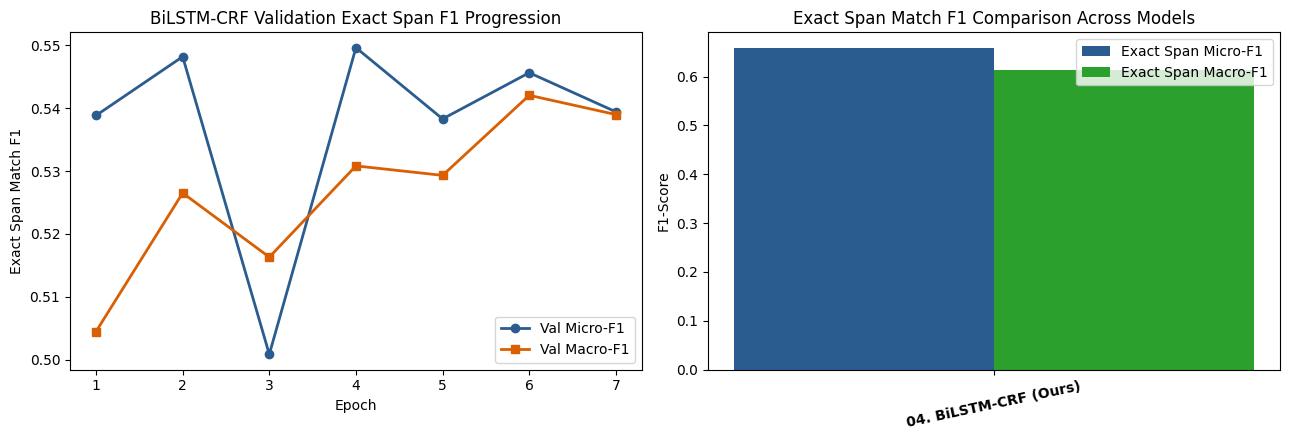

In [6]:
bilstm_metrics, y_pred_bilstm = evaluate_model(model, test_loader)

with open("bilstm_crf_metrics.json", "w") as f:
    json.dump(bilstm_metrics, f, indent=2)

print("=================================================================")
print("   BiLSTM-CRF — EXACT SPAN MATCH EVALUATION (TEST SET)           ")
print("=================================================================")
print(f"Exact Span Micro Precision : {bilstm_metrics['micro_precision']:.4f}")
print(f"Exact Span Micro Recall    : {bilstm_metrics['micro_recall']:.4f}")
print(f"Exact Span Micro F1-Score  : {bilstm_metrics['micro_f1']:.4f}")
print("-----------------------------------------------------------------")
print(f"Exact Span Macro Precision : {bilstm_metrics['macro_precision']:.4f}")
print(f"Exact Span Macro Recall    : {bilstm_metrics['macro_recall']:.4f}")
print(f"Exact Span Macro F1-Score  : {bilstm_metrics['macro_f1']:.4f}")
print("-----------------------------------------------------------------")
print(f"Invalid BIO Transitions    : {bilstm_metrics['invalid_bio_transitions']}")
print("=================================================================")

# Load HMM and CRF metrics if available for side-by-side comparison
comparison_rows = []
for name, fname in [("02. Baseline HMM", "hmm_metrics.json"),
                    ("03. Linear-Chain CRF", "crf_metrics.json"),
                    ("04. BiLSTM-CRF (Ours)", "bilstm_crf_metrics.json")]:
    if os.path.exists(fname):
        with open(fname, "r") as f:
            m = json.load(f)
        comparison_rows.append({
            "Model": name,
            "Exact Span Micro-P": m["micro_precision"],
            "Exact Span Micro-R": m["micro_recall"],
            "Exact Span Micro-F1": m["micro_f1"],
            "Exact Span Macro-F1": m["macro_f1"],
            "Invalid BIO (O->I)": m["invalid_bio_transitions"]
        })

comp_df = pd.DataFrame(comparison_rows)
display(comp_df.style.format({
    "Exact Span Micro-P": "{:.4f}",
    "Exact Span Micro-R": "{:.4f}",
    "Exact Span Micro-F1": "{:.4f}",
    "Exact Span Macro-F1": "{:.4f}"
}))

# Plot training curves & model comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

hist_df = pd.DataFrame(history)
axes[0].plot(hist_df["epoch"], hist_df["val_micro_f1"], marker="o", label="Val Micro-F1", color="#2b5c8f", linewidth=2)
axes[0].plot(hist_df["epoch"], hist_df["val_macro_f1"], marker="s", label="Val Macro-F1", color="#d95f02", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Exact Span Match F1")
axes[0].set_title("BiLSTM-CRF Validation Exact Span F1 Progression")
axes[0].legend()

x = np.arange(len(comp_df))
width = 0.35
axes[1].bar(x - width/2, comp_df["Exact Span Micro-F1"], width, label="Exact Span Micro-F1", color="#2b5c8f")
axes[1].bar(x + width/2, comp_df["Exact Span Macro-F1"], width, label="Exact Span Macro-F1", color="#2ca02c")
axes[1].set_xticks(x)
axes[1].set_xticklabels(comp_df["Model"], rotation=12, fontweight="bold")
axes[1].set_ylabel("F1-Score")
axes[1].set_title("Exact Span Match F1 Comparison Across Models")
axes[1].legend()

plt.tight_layout()
plt.show()